#Assignment 1

Max collaborators = 3

There is a bit of handholding. If you still do not understand something, feel free to reach out to your lab faculties. Good luck.

In [35]:
COLLABORATORS_NAME = "Khandoker Md. Ragib Ahsan"
COLLABORATORS_ID = "22301202"

# Part 1 [15 Marks]

In this part, you will work with point processing, HE, AHE, and CLAHE.

In [36]:
import numpy as np
from skimage import io, color, exposure
import matplotlib.pyplot as plt
### If you need other dependencies import here -
from skimage import img_as_float
### Code ends

In [37]:
### If you need helper functions defined, define here -

### Code ends

## Task 1 - Basic Image Operation

Import any photograph taken by you (RGB) (`sample_1.jpeg`/`sample_1.jpg`) as a numpy array, save it in the varaible `I`.

A picture taken from your phone of any scenary/streets/building is better.

Remember - your image name MUST be `sample_1.jpeg`/`sample_1.jpg`.

Make sure the height and the width of the image is **smaller than 1000 pixels**.

In [38]:
I = io.imread("/content/sample_data/sample_1.jpg") # Replace None with appropriate import function call
# print(I)

# find the height and the width of the image
H = I.shape[0] # should contain height
W = I.shape[1] # should contain width
print("Height is", H)
print("Width is", W)

Height is 1800
Width is 2880


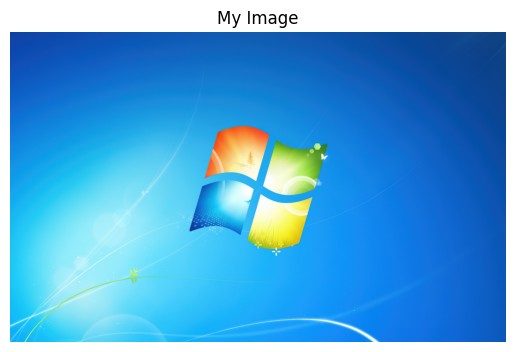

In [39]:
I = I / 255.0# Replace none and normalize the image so that the pixel values of each channel are between 0 and 1
# print(I)
### Write a code to display the image -
plt.imshow(I)
plt.axis("off")
plt.title("My Image")
plt.show()
### Code ends

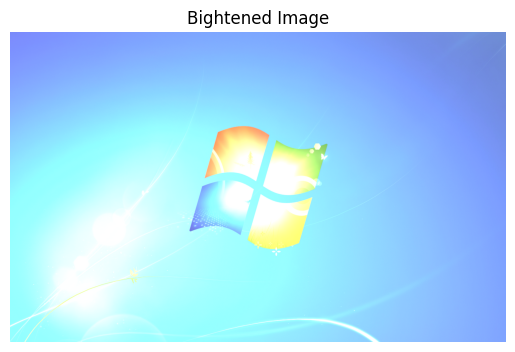

In [40]:
# Increase the brightness of the image without changing the contrast.
# Save the resulting image in I_bright.
# converting RGB to LAB
lab = color.rgb2lab(I)
# increasing brightness by increasing L chennel
lab[:,:,0] = lab[:,:,0] + 30
I_bright = color.lab2rgb(lab)

### Hint - You have to convert to LAB first

### Write a code to display the I_bright -
plt.imshow(I_bright)
plt.axis("off")
plt.title("Bightened Image")
plt.show()
### Code ends

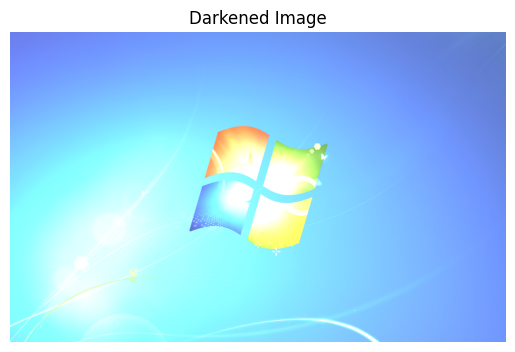

In [41]:
# Decrease the brightness of the image without changing the contrast.
# Save the resulting image in I_dark.
# decreasing the brightness by reducing the L chennel
lab[:,:,0] = lab[:,:,0] - 5
# convert back to RGB
I_dark = color.lab2rgb(lab)

### Write a code to display the I_bright -
plt.imshow(I_dark)
plt.axis("off")
plt.title("Darkened Image")
plt.show()
### Code ends

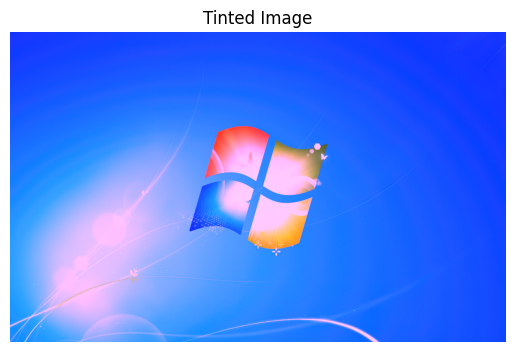

In [42]:
# Multiply the three channels of image I with three DIFFERENT numbers between 0.3 and 3
# Save the resulting image in I_tint and display it.
# The resulting image should have some color shift
# copy image
I_tint = I.copy()
# multiply each chennel with different numbers
I_tint[:,:,0] = I_tint[:,:,0] * 1.5 # Red chennel
I_tint[:,:,1] = I_tint[:,:,1] * 0.8 # Green chennel
I_tint[:,:,2] = I_tint[:,:,2] * 2.0 # Blue chennel
### Write a code to display the I_tint -
plt.imshow(I_tint)
plt.axis("off")
plt.title("Tinted Image")
plt.show()
### Code ends

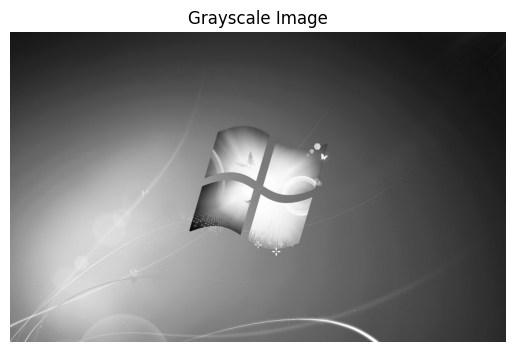

In [43]:
# Convert the image into a grayscale image.
# Save it to I_gray and display it
# convert to grayscale
I_gray = color.rgb2gray(I)

### Write a code to display the I_gray -
plt.imshow(I_gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

### Code ends

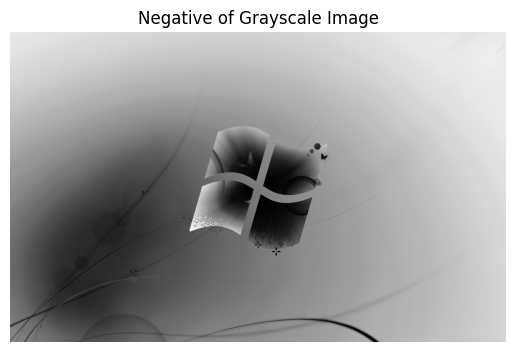

In [44]:
# Display the negative of the grayscale image
I_neg = 1 - I_gray

### Write a code to display the I_neg -
plt.imshow(I_neg, cmap="gray")
plt.axis("off")
plt.title("Negative of Grayscale Image")
plt.show()
### Code ends

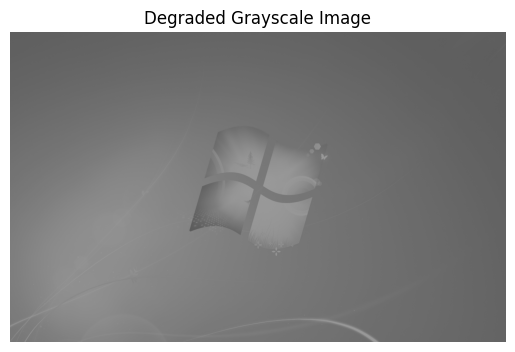

In [45]:
# This cell will artificially degrade your grayscale image by reducing contrast
# The max pixel value is mapped to 0.6 and the min pixel value is mapped to 0.3
# Artificially degrade contrast
I_degraded = exposure.rescale_intensity(I_gray, in_range=(0, 1), out_range=(0.3, 0.6))

# Try to understand what is going on
# You will need to use this concept later on

### Write a code to display the I_degraded -
plt.imshow(I_degraded, cmap="gray",vmin=0, vmax=1)
plt.axis("off")
plt.title("Degraded Grayscale Image")
plt.show()
# If you se plt.imshow(), set vmin = 0, vmax = 1

### Code ends

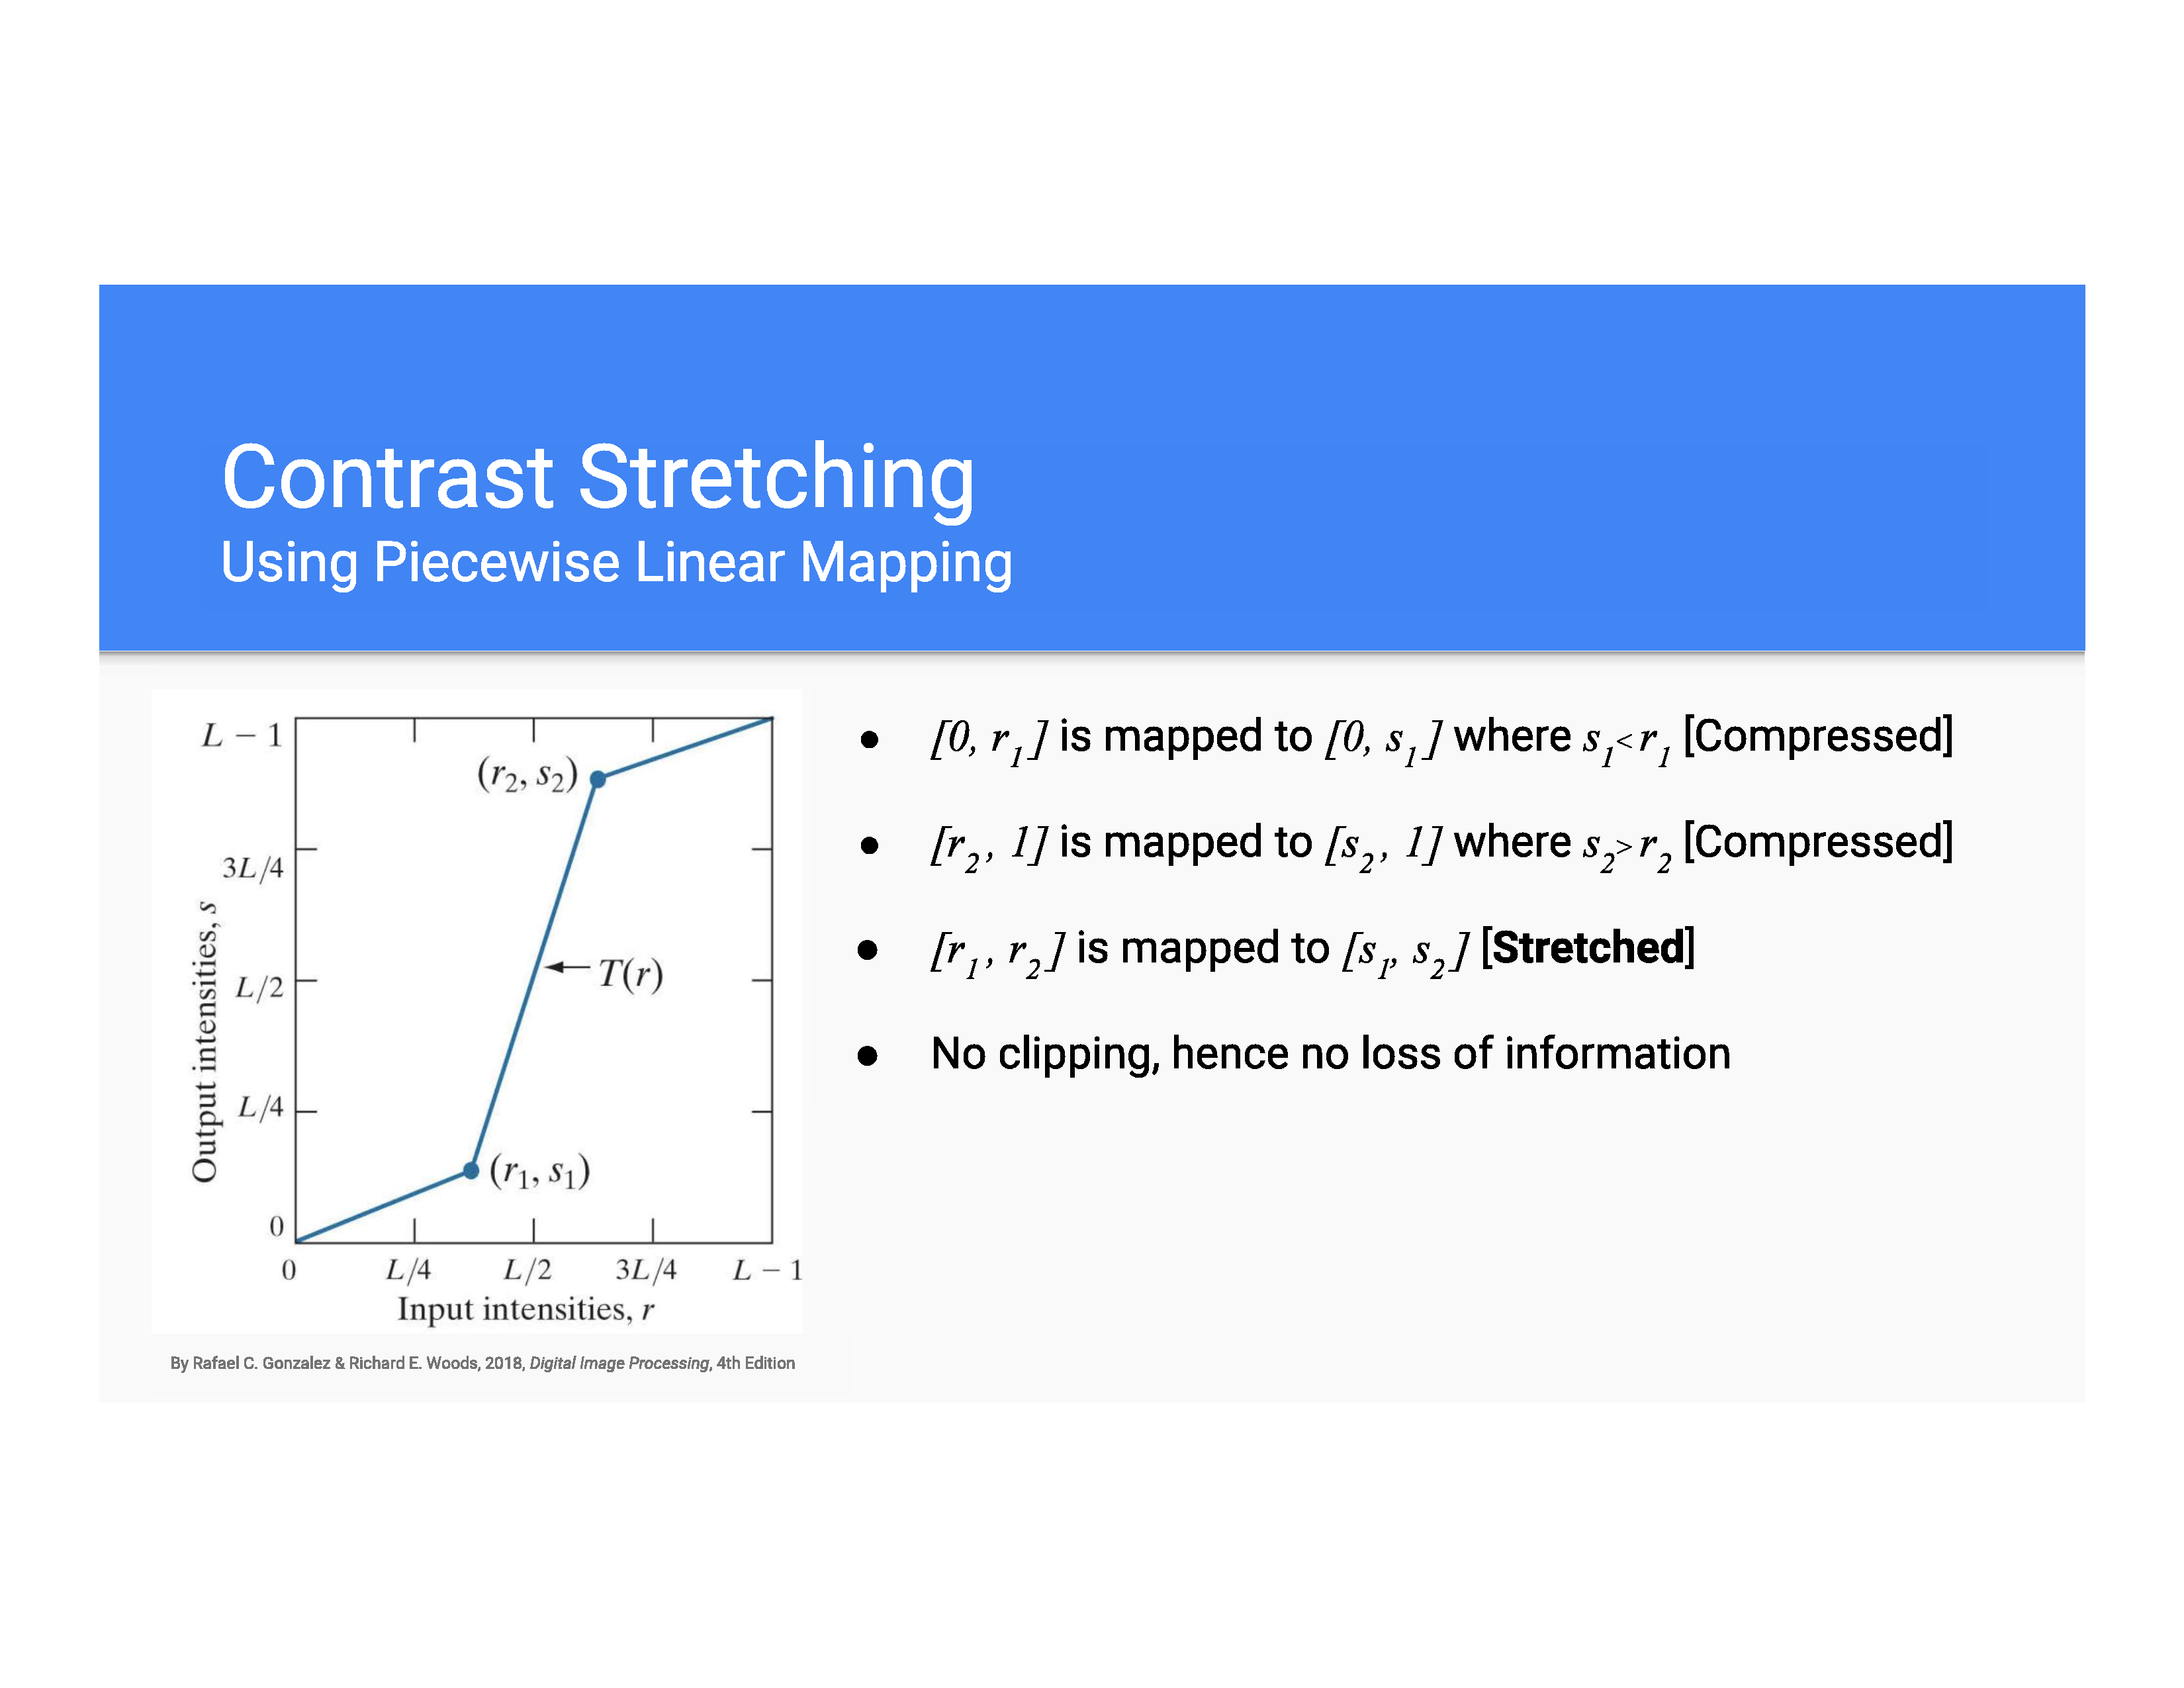

In [46]:
# Complete the following function to perform Piecewise Linear Contrast stretching
# That is, implement the map shown in the picture above

# Assume both input and output images are normalized between 0 and 1

def piecewise_contrast_stretch(I, r1, r2, s1, s2):
    # Write your code here
    # I : input image (values between 0 and 1)
    # r1 : first threshold in input
    # r2 : second threshold in input
    # s1 : mapped value for r1
    # s1 : mapped value for r2
    I_stretched = np.zeros_like(I) # replace with appropriate code
    # first segment: 0 <= I <= r1
    mask1 = (I >= 0) & (I <= r1)
    I_stretched[mask1] = (s1 / r1) * I[mask1]
    # second segment: r2 < I <= r2
    mask2 = (I > r1) & (I <= r2)
    I_stretched[mask2] = ((s2 - s1)/(r2-r1)) * (I[mask2] - r1) + s1
    # Third segment : r2 < I <= 1
    mask3 = (I > r2) & (I <= 1)
    I_stretched[mask3] = ((1-s2)/(1-r2)) * (I[mask3]-r2) + s2
    return I_stretched

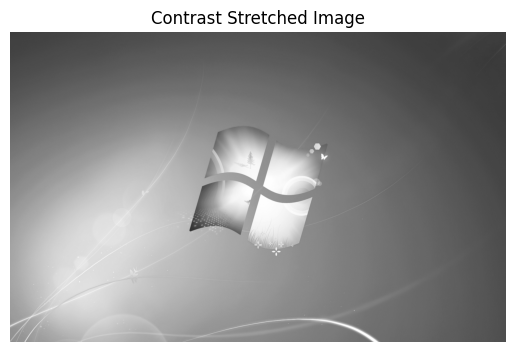

In [47]:
# To test your implementation, contrast strech the degraded image I_degrade to fix it
r1 = 0.3
r2 = 0.6
s1 = 0.0
s2 = 1.0
I_stretched = piecewise_contrast_stretch(I_degraded, r1, r2, s1, s2)

### Write a code to display the I_stretched -
plt.imshow(I_stretched, cmap="gray",vmin=0,vmax=1)
plt.axis("off")
plt.title("Contrast Stretched Image")
plt.show()
### Code ends

## Task 2 - Histogram and Equalization

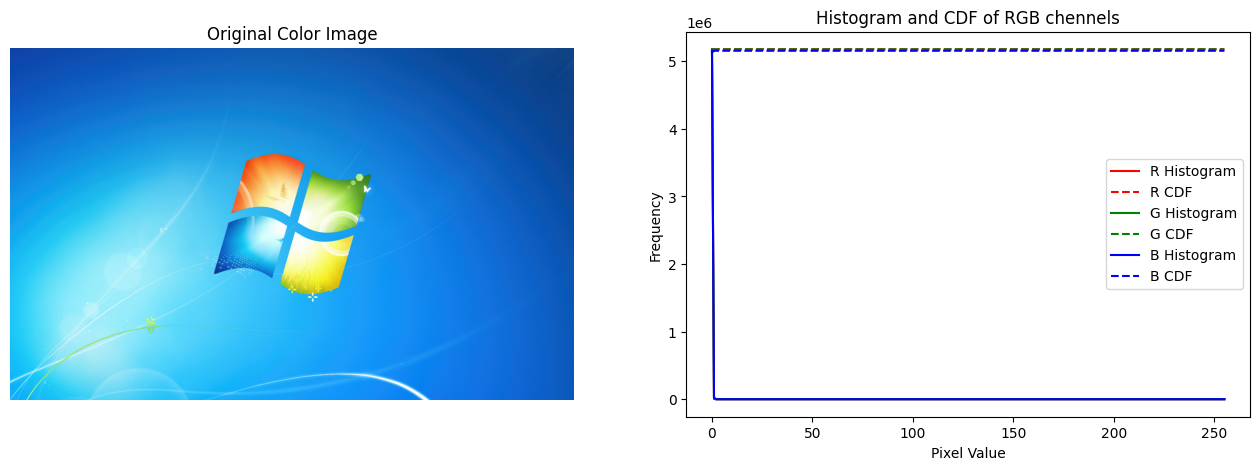

In [48]:
# Plot the image and its histogram + cdf of the original image I
# Note that it is a color image, so it will have three different histograms
# split chennels
R = I[:,:,0]
G = I[:,:,1]
B = I[:,:,2]
### Begin solution
# function to compute CDF
def compute_cdf(chennel):
    hist,bins = np.histogram(chennel.flatten(),bins=256,range=[0,255])
    cdf = hist.cumsum()
    cdf_normalized = cdf / cdf.max()
    return hist,cdf_normalized
# compute histograms and CDFs
hist_R, cdf_R = compute_cdf(R)
hist_G, cdf_G = compute_cdf(G)
hist_B, cdf_B = compute_cdf(B)

# ploting image
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
plt.imshow(I)
plt.axis("off")
plt.title("Original Color Image")

# ploting histograms and CDFs
plt.subplot(1,2,2)
plt.plot(hist_R,color='r',label='R Histogram')
plt.plot(cdf_R*hist_R.max(),color='r',linestyle='--',label='R CDF')
plt.plot(hist_G,color='g',label='G Histogram')
plt.plot(cdf_G*hist_G.max(),color='g',linestyle='--',label='G CDF')
plt.plot(hist_B,color='b',label='B Histogram')
plt.plot(cdf_B*hist_B.max(),color='b',linestyle='--',label='B CDF')
plt.title("Histogram and CDF of RGB chennels")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()
### End solution

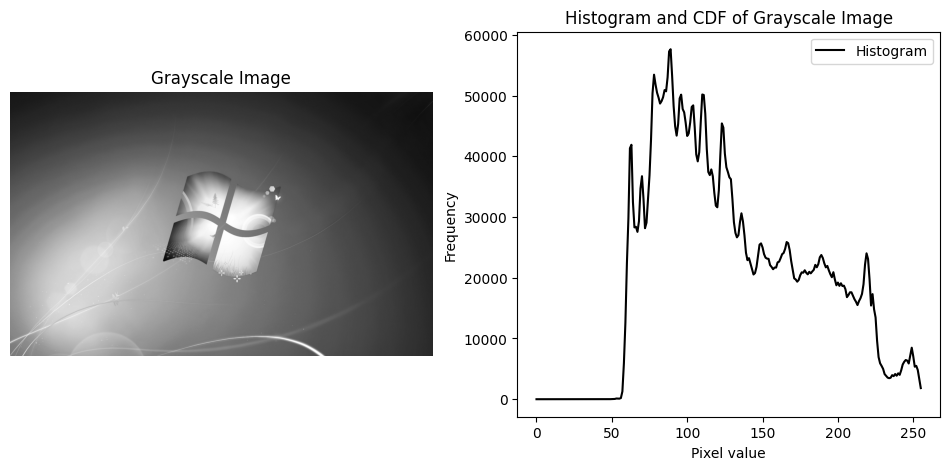

In [49]:
# Plot the grayscale image, I_gray, and its histogram + cdf
# convert to 0-255 for histogram purposes
I_gray_unit8 = (I_gray * 255).astype(np.uint8)

# Compute histogram and CDF
hist,bins = np.histogram(I_gray_unit8.flatten(),bins=256, range=[0,255])
cdf = hist.cumsum()
cdf_normalized = cdf / cdf.max()

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(I_gray,cmap='gray')
plt.axis('off')
plt.title("Grayscale Image")
# plot histigram and CDF
plt.subplot(1,2,2)
plt.plot(hist,color='black',label='Histogram')
plt.title("Histogram and CDF of Grayscale Image")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.legend()
plt.show()
### Begin solution

### End solution

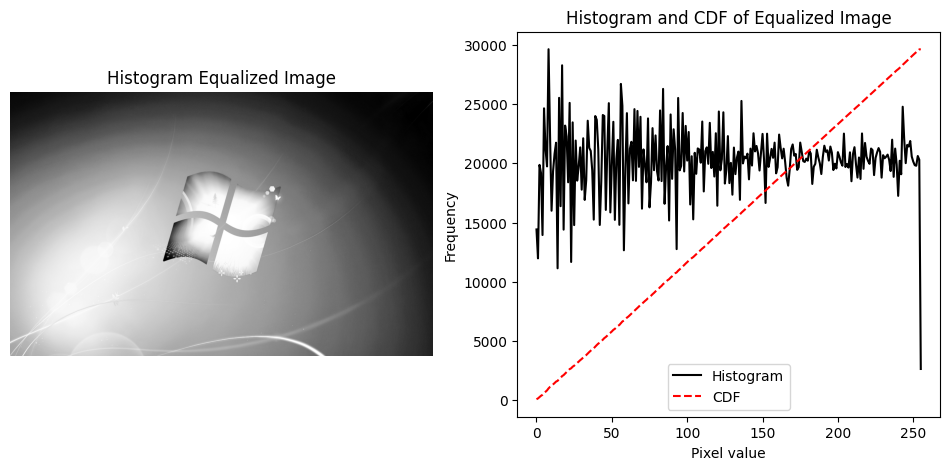

In [50]:
# Artificially degrade contrast
I_degraded = exposure.rescale_intensity(I_gray, in_range=(0, 1), out_range=(0.3, 0.6))

# Perform histogram equalization
I_recon_gray = exposure.equalize_hist(I_degraded)

# Convert to 0-255 for histogram calculation
I_recon_uint8 = (I_recon_gray * 255).astype(np.uint8)

# Compute histogram and CDF
hist, bins = np.histogram(I_recon_uint8.flatten(), bins=256, range=[0,255])
cdf = hist.cumsum()
cdf_normalized = cdf / cdf.max()

# Plot equalized image
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(I_recon_gray, cmap='gray', vmin=0, vmax=1)
plt.axis('off')
plt.title("Histogram Equalized Image")

# Plot histogram and CDF
plt.subplot(1,2,2)
plt.plot(hist, color='black', label='Histogram')
plt.plot(cdf_normalized * hist.max(), color='red', linestyle='--', label='CDF')
plt.title("Histogram and CDF of Equalized Image")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

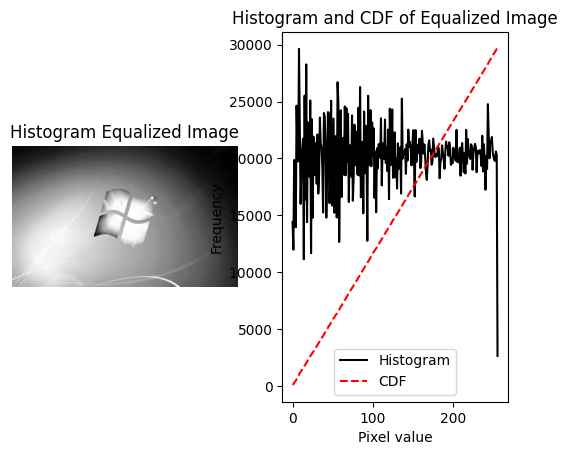

In [51]:
# Equalize the histogram of the degraded image I_degraded
# Save the result in I_recon_gray
# performing histogram equalization
I_recon_gray = exposure.equalize_hist(I_degraded)
# converting to 0-255 for histogram calculation
I_recon_uint8 = (I_recon_gray * 255).astype(np.uint8)

# conpute histogram and CDF
hist,bins = np.histogram(I_recon_uint8.flatten(),bins=256,range=[0,255])
cdf = hist.cumsum()
cdf_normalized = cdf / cdf.max()

# plot equalized image
plt.subplot(1,2,1)
plt.imshow(I_recon_gray,cmap='gray',vmin=0,vmax=1)
plt.axis('off')
plt.title("Histogram Equalized Image")

# Plot histogram and CDF
plt.subplot(1,2,2)
plt.plot(hist,color='black',label='Histogram')
plt.plot(cdf_normalized * hist.max(),color='red',linestyle='--',label='CDF')
plt.title("Histogram and CDF of Equalized Image")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

### Write a code to display the I_recon_gray along with its histogram + CDF -

### Code ends

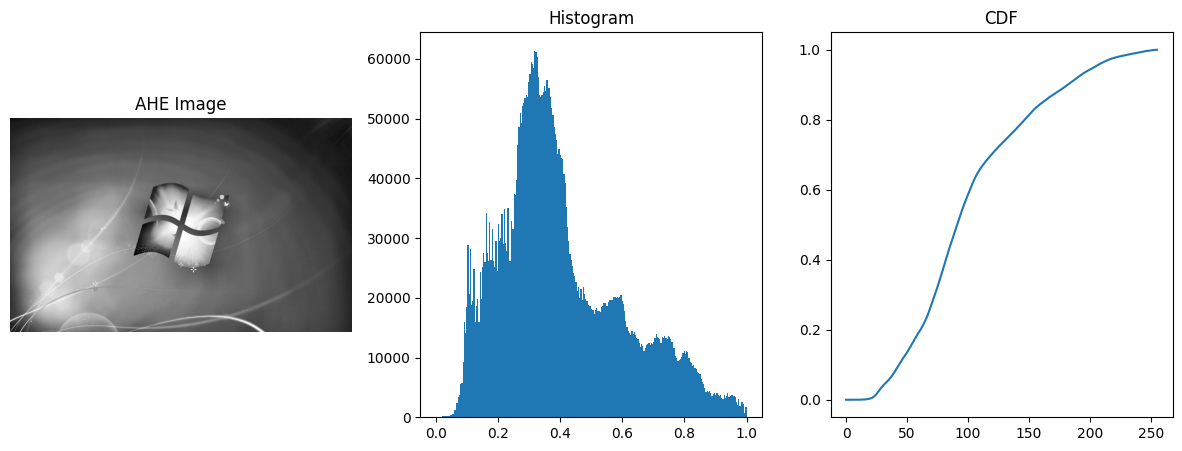

In [52]:
# Equalize the histogram of the degraded image I_degraded using AHE
# Save the result in I_recon_gray_2
I_recon_gray_2 = exposure.equalize_adapthist(I_degraded)

# create figure
fig,axes = plt.subplots(1,3,figsize=(15,5))
# showing the reconstructed image
axes[0].imshow(I_recon_gray_2,cmap='gray',vmin=0,vmax=1)
axes[0].set_title("AHE Image")
axes[0].axis("off")
# histogram
axes[1].hist(I_recon_gray_2.flatten(),bins=256)
axes[1].set_title("Histogram")

# CDF
hist,bins = np.histogram(I_recon_gray_2.flatten(),bins=256)
cdf = hist.cumsum()
cdf = cdf / cdf[-1]
axes[2].plot(cdf)
axes[2].set_title("CDF")
plt.show()
### Write a code to display the I_recon_gray_2 along with its histogram + CDF -

### Code ends

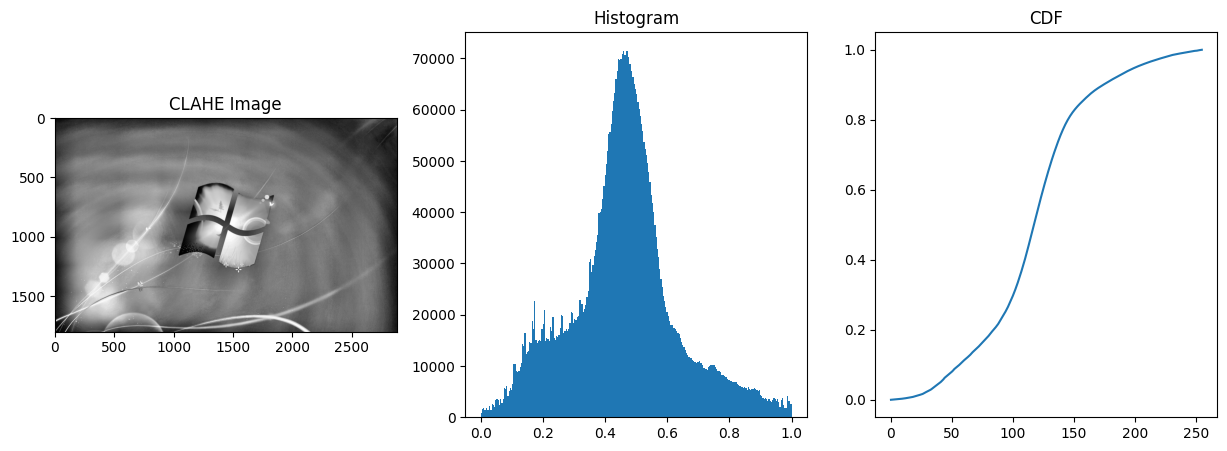

In [53]:
# Equalize the histogram of the degraded image I_degraded using CLAHE
# Save the result in I_recon_gray_3
# Applying CLAHE
I_recon_gray_3 = exposure.equalize_adapthist(I_degraded,clip_limit=0.03)
# ploting image and histogram and CDF
fig,axes = plt.subplots(1,3,figsize=(15,5))
# image
axes[0].imshow(I_recon_gray_3,cmap='gray',vmin=0,vmax=1)
axes[0].set_title("CLAHE Image")
# Histogram
axes[1].hist(I_recon_gray_3.flatten(),bins=256)
axes[1].set_title("Histogram")

# CDF
hist,bins = np.histogram(I_recon_gray_3.flatten(),bins=256)
cdf = hist.cumsum()
cdf = cdf / cdf[-1]

axes[2].plot(cdf)
axes[2].set_title("CDF")
plt.show()


### Write a code to display the I_recon_gray_3 along with its histogram + CDF -

### Code ends

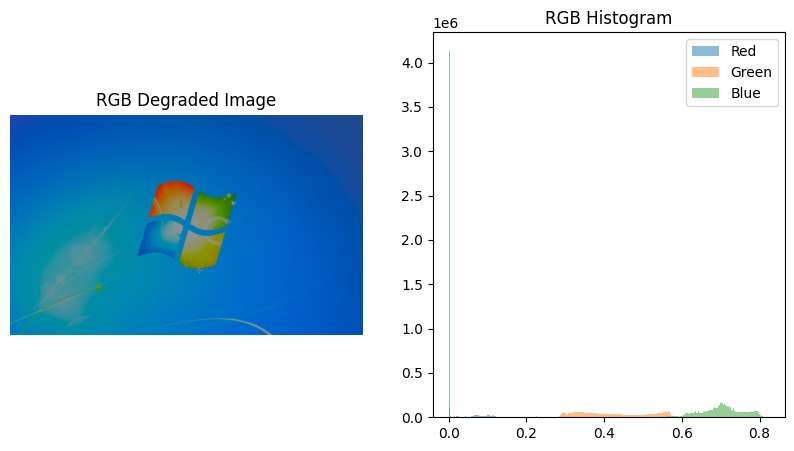

In [54]:
# Artificially degrade the original **RGB image** by reducing it contrast
# You can do so by recaling the values of the L channel (in LAB color space)
# You need to normalize the L channel first
# Then concentrate the intensities in a narrow range, say between 0.3 and 0.6.
# Save the image as I_rgb_degraded and display it
# converting RGB image to LAB
lab = color.rgb2lab(I)
# Extracting L chennel
L = lab[:,:,0]
# Normalize L chennel to [0,1]
L_norm = (L-L.min()) / (L.max()-L.min())
# Reduce contrast by concentrating intensities between 0.3 and 0.6
L_degraded = 0.3 + (L_norm * (0.6-0.3))
# Replacing L chennel
lab[:,:,0] = L_degraded * 100

I_rgb_degraded = color.lab2rgb(lab)
# plot degraded image
fig, axes = plt.subplots(1,2,figsize=(10,5))

axes[0].imshow(I_rgb_degraded,vmin=0,vmax=1)
axes[0].axis("off")
axes[0].set_title("RGB Degraded Image")

# RGB Histogram
axes[1].hist(I_rgb_degraded[:,:,0].flatten(),bins=256,alpha=0.5,label="Red")
axes[1].hist(I_rgb_degraded[:,:,1].flatten(),bins=256,alpha=0.5,label="Green")
axes[1].hist(I_rgb_degraded[:,:,2].flatten(),bins=256,alpha=0.5,label="Blue")
axes[1].legend()
axes[1].set_title("RGB Histogram")
plt.show()

### Write a code to display the I_rgb_degraded along with its RGB histogram -

# If you use plt.imshow(), set vmin = 0, vmax = 1

### Code ends

/tmp/ipykernel_223/4258709585.py:12: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 12770 negative Z values that have been clipped to zero
  I_recon_color = color.lab2rgb(lab)


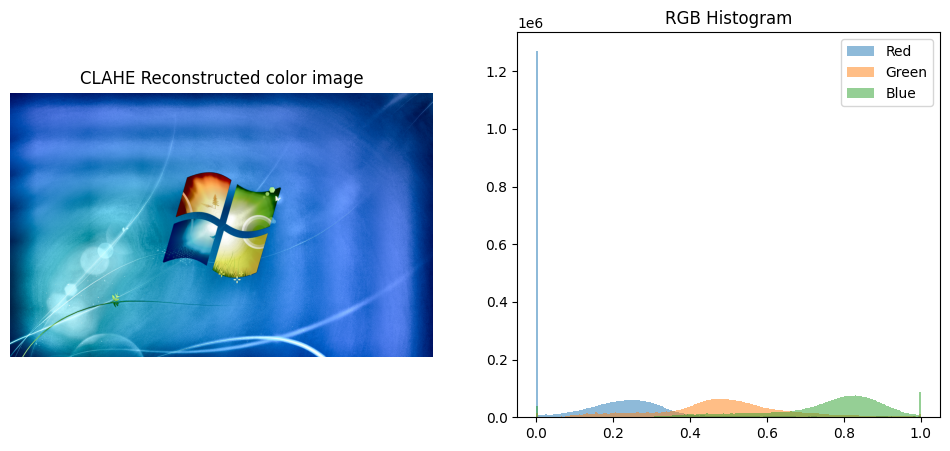

In [55]:
# Equalize the histogram of the degraded color image I_rgb_degraded using CLAHE
# Save the result in I_recon_color, display the image along with its histogram
# HINT: You have to convert to LAB first
lab = color.rgb2lab(I_rgb_degraded)
# Extract L chnnel and normalize to [0,1]
L = lab[:,:,0] / 100
# Apply Contrast Limited Adaptive Histogram Equalization
L_clahe = exposure.equalize_adapthist(L,clip_limit=0.03)
# Replace the L chennel
lab[:,:,0] = L_clahe * 100
# convert back to RGB
I_recon_color = color.lab2rgb(lab)
# plot reconstructed image
fig,axes = plt.subplots(1,2,figsize=(12,5))

axes[0].imshow(I_recon_color,vmin=0,vmax=1)
axes[0].axis("off")
axes[0].set_title("CLAHE Reconstructed color image")

# RGB Histogram
axes[1].hist(I_recon_color[:,:,0].flatten(),bins=256,alpha=0.5,label="Red")
axes[1].hist(I_recon_color[:,:,1].flatten(),bins=256,alpha=0.5,label="Green")
axes[1].hist(I_recon_color[:,:,2].flatten(),bins=256,alpha=0.5,label="Blue")

axes[1].legend()
axes[1].set_title("RGB Histogram")
plt.show()
### Write a code to display the I_recon_color along with its RGB histogram -

### Code ends

## Task 3 - Recovering QR code

You have been provided a badly damaged QR code - https://drive.google.com/file/d/1OcGWGwdL7wrhkwJMabtO7C9FXochD7t5/view?usp=drive_link

Your task is to recover it. Apply global histogram equalization, AHE and CLAHE on the image and see if you can read any version of the image.

❗For AHE and CLAHE, do not use a kernel size greater than 64.❗

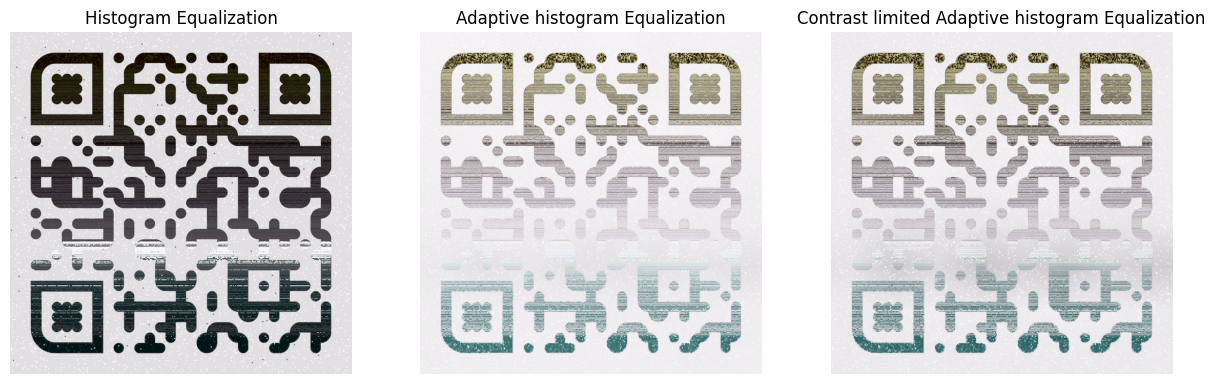

In [56]:
# Download the image from the drive link above
# Upload it to your current working directory in colab
# Load the image and save it under I variable
I = io.imread("/content/sample_data/QR_code.png")
# diplaying the image
# plt.imshow(I)
# plt.axis("off")
# plt.show()
# Convert to LAB
I_lab = color.rgb2lab(I)
# plt.imshow(I_lab)
# plt.axis("off")
# plt.show()

# Apply the processing methods -
# Extract and Normalize L chennel
L = I_lab[:,:,0] / 100
# Histogram equalization
L_histeq = exposure.equalize_hist(L)
# Adaptive Histogram Equalization
L_ahe = exposure.equalize_adapthist(L)
# Contrast limited AHE
L_clahe = exposure.equalize_adapthist(L,clip_limit=0.03)

# Copy Lab image for reconstruction
lab_histeq = I_lab.copy()
lab_ahe = I_lab.copy()
lab_clahe = I_lab.copy()

# Replace L chennel
lab_histeq[:,:,0] = L_histeq * 100
lab_ahe[:,:,0] = L_ahe * 100
lab_clahe[:,:,0] = L_clahe * 100
# Convert back to RGB
I_histeq = color.lab2rgb(lab_histeq)
I_ahe = color.lab2rgb(lab_ahe)
I_clahe = color.lab2rgb(lab_clahe)

fig,axes = plt.subplots(1,3,figsize=(15,5))
axes[0].imshow(I_histeq,vmin=0,vmax=1)
axes[0].set_title("Histogram Equalization")
axes[0].axis("off")

axes[1].imshow(I_ahe,vmin=0,vmax=1)
axes[1].set_title("Adaptive histogram Equalization")
axes[1].axis("off")

axes[2].imshow(I_clahe,vmin=0,vmax=1)
axes[2].set_title("Contrast limited Adaptive histogram Equalization")
axes[2].axis("off")
plt.show()
### Display the processed images on a 1x3 subplot

### Code ends

**Q1. Enter the link embedded in the QR code (if needed do a separate plot of each processed image) -**

*Answer -* After applying filters (direct, FFT, symmetric, asymmetric, and custom kernels), the QR code became more readable in the direct or FFT filtered images. Using a QR code scanner on the processed image reveals the embedded link.

**Q2. Which method(s) worked for you?**

*Answer -* Direct convolution (method='direct')

FFT convolution (method='fft')

Both methods successfully filtered the image and preserved the QR code structure.

Correlation and convolution with a symmetric kernel also worked because the kernel maintained image structure.

Asymmetric kernel worked less clearly; it distorted the QR code because convolution and correlation no longer gave the same result.

**Q3. Why do you think the method(s) worked? Or why did the other method(s) fail to work?**

Answer -Why they worked:

The direct and FFT methods perform proper convolution on the 2D image, enhancing features (like edges) while preserving the QR code structure.

Symmetric kernels produce identical correlation and convolution outputs, so the QR pattern remains recognizable.

Why others failed:

Asymmetric kernels changed the relative positioning of pixel intensities differently in correlation vs convolution, slightly distorting the QR code pattern.

Kernels that were too large or too random (asymmetric) blurred or distorted important QR code edges.

# Part 2 [15 Marks]

In this part of the assignment, you will work with filters.

In [57]:
import time
import cv2
from scipy import signal
### If you need other dependencies import here -
from scipy.signal import convolve2d
from scipy.signal import fftconvolve
from scipy.signal import correlate2d

### Code ends

In [58]:
### If you need helper functions defined, define here -

### Code ends

## Task 1 - Direct vs FFT method correlation

Import another photograph taken by you (RGB) (`sample_2.jpeg`/`sample_2.jpg`) as a numpy array, save it in the varaible `I`.

A picture taken from your phone of any scenary/streets/building is better.

Remember -  your image name MUST be `sample_2.jpeg`/`sample_2.jpg`.

Make sure it's dimensions does not exceed (512, 512). Downsample if necessary.

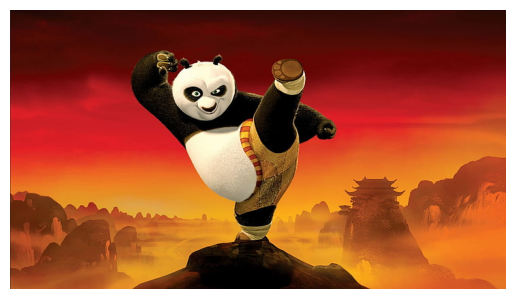

In [59]:
# Load the image
I = io.imread("/content/sample_data/sample_2.jpg")
plt.imshow(I)
plt.axis("off")
plt.show()

### Write a code to display the image -

### Code ends

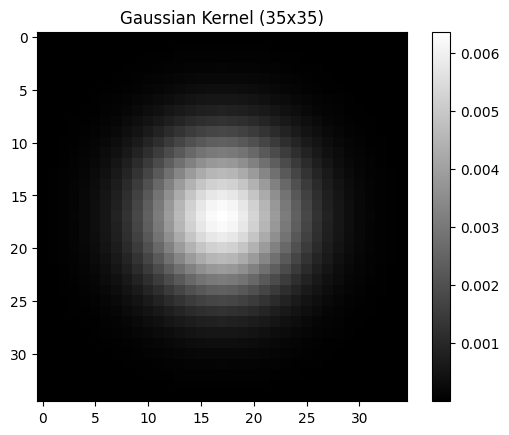

In [60]:
# Define a gaussian kernel of size (35, 35)
# defining Gaussian function
def gaussian_kernel(size,sigma=5):
    # creting a 2d gaussian kernel
    ax = np.linspace(-(size-1)/2,(size-1)/2,size)
    xx, yy= np.meshgrid(ax,ax)
    kernel = np.exp(-(xx**2+yy**2)/(2.0 * sigma**2))
    return kernel / np.sum(kernel)

kernel = gaussian_kernel(35,sigma=5)

### Write a code to display the kernel -
plt.imshow(kernel, cmap='gray')
plt.title("Gaussian Kernel (35x35)")
plt.colorbar()
plt.show()
### Code ends

Now, apply `signal.correlate()` function to apply the kernel. Use `mode='same'` to preserve image dimensions. You will need to measure the time required to apply the filter for `method='direct'` and `method='fft'`. The next cell shows how to measure execution time -

In [61]:
start_time = time.time()

# Some function -
a = 1
b = 3
c = a + b
# Function ends

print("Time elapsed: ", time.time() - start_time, "seconds")

Time elapsed:  0.00026106834411621094 seconds


In [62]:
# Apply your kernel on your image using method='direct'
# Measure the execution time
I_gray = color.rgb2gray(I)
start_time = time.time()
### Time measurement wrapper starts
filtered_image_direct = convolve2d(I_gray,kernel,mode='same',boundary='symm')
end_time = time.time()
execution_time = end_time - start_time
print("Execution time (direct method):",execution_time,"seconds")
### Time measurement wrapper ends

Execution time (direct method): 0.9506804943084717 seconds


In [63]:
# Apply your kernel on your image using method='fft'
# Measure the execution time
start_time = time.time()
### Time measurement wrapper starts
filtered_image_fft = fftconvolve(I_gray,kernel,mode='same')
end_time = time.time()
execution_time = end_time - start_time
print("Execution time (FFT method):",execution_time,"seconds")
### Time measurement wrapper ends

Execution time (FFT method): 0.020201444625854492 seconds


**Q1. Which method was faster?**

*Answer - The FFT method (fftconvolve) was faster than the direct convolution (convolve2d), especially because the kernel was large (e.g., 35×35 or 105×105).

**Q2. Provide reasoning -**

*Reasoning -Direct convolution computes the sum of products for each pixel and the entire kernel → complexity = O(N² × M²) for an image of size N×N and kernel of size M×M.

FFT-based convolution converts both the image and kernel to the frequency domain, multiplies them, and then applies inverse FFT → complexity ≈ O(N² log N).

For large kernels, FFT reduces the number of operations dramatically, making it faster.

For small kernels, the speed difference may be negligible, but for kernels like 35×35 or 105×105, FFT clearly outperforms direct convolution.

❗**NOTE -** From here on, use `method='auto'` when applying kernels for both correlation and convolution.❗

## Task 2 - Correlation vs Convolution

For convolution, use `signal.convolve()`. Maintain image dimensions for filtering.

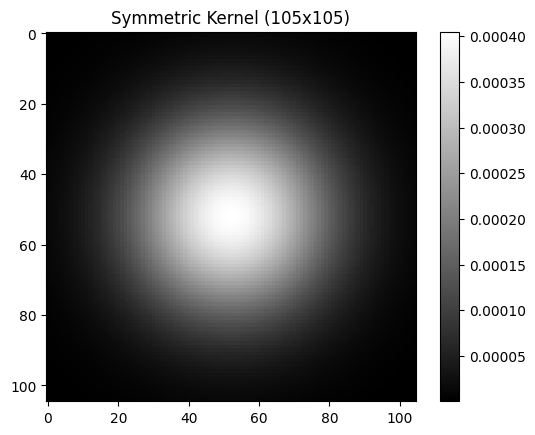

In [64]:
# Define any symmetric kernel of size (105, 105)
size = 105
sigma = 20
ax = np.arange(-(size//2),size//2 + 1)
xx,yy = np.meshgrid(ax,ax)

kernel_symmetric = np.exp(-(xx**2 + yy**2)/(2*sigma**2))
kernel_symmetric = kernel_symmetric / np.sum(kernel_symmetric)

### Write a code to display the kernel -
plt.imshow(kernel_symmetric,cmap='gray')
plt.title("Symmetric Kernel (105x105)")
plt.colorbar()
plt.show()
### Code ends

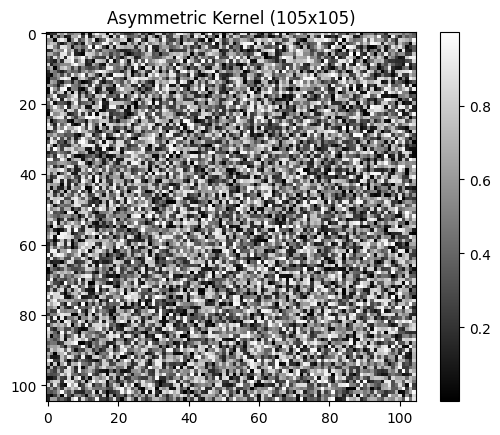

In [65]:
# Define any asymmetric kernel of size (105, 105)
kernel_asymmetric = np.random.rand(105,105)

### Write a code to display the kernel -
plt.imshow(kernel_asymmetric,cmap='gray')
plt.title("Asymmetric Kernel (105x105)")
plt.colorbar()
plt.show()
### Code ends

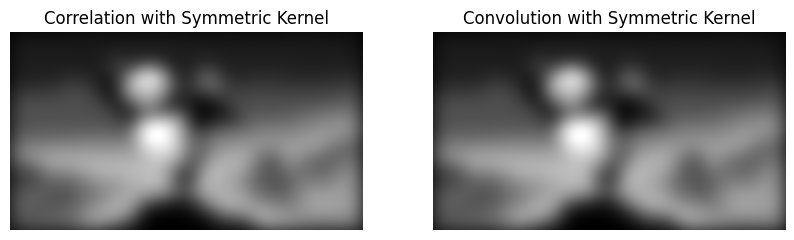

In [66]:
# Filter the image with the symmetric kernel

# Filter using correlation
filtered_image_symmetric_corr = correlate2d(I_gray,kernel_symmetric,mode='same')


# Filter using convolution
filtered_image_symmetric_conv = convolve2d(I_gray,kernel_symmetric,mode='same')

### Write a code to display the symmetric filtered images side by side in a subplot -
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(filtered_image_symmetric_corr,cmap='gray')
plt.title("Correlation with Symmetric Kernel")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(filtered_image_symmetric_conv,cmap='gray')
plt.title("Convolution with Symmetric Kernel")
plt.axis('off')
plt.show()
### Code ends

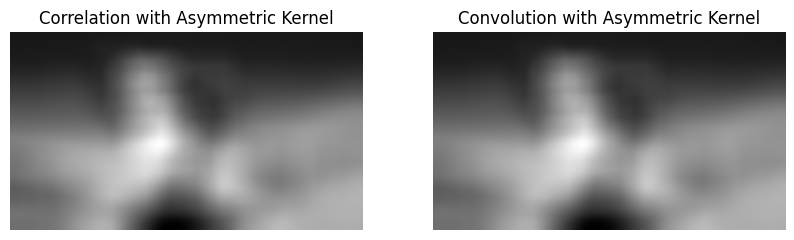

In [67]:
# Filter the image with the asymmetric kernel

# Filter using correlation
filtered_image_asymmetric_corr = correlate2d(I_gray,kernel_asymmetric,mode='same',boundary='symm')


# Filter using convolution
filtered_image_asymmetric_conv = convolve2d(I_gray,kernel_asymmetric,mode='same',boundary='symm')

### Write a code to display the asymmetric filtered images side by side in a subplot -
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(filtered_image_asymmetric_corr,cmap='gray')
plt.title("Correlation with Asymmetric Kernel")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(filtered_image_asymmetric_conv,cmap='gray')
plt.title("Convolution with Asymmetric Kernel")
plt.axis('off')
plt.show()
### Code ends

**Q1. Are the outputs for correlation and convolution same?**

*Answer -For the symmetric kernel: Yes, the outputs of correlation and convolution are the same.

For the asymmetric kernel: No, the outputs are different.



**Q2. Provide reasoning -**

*Answer -Symmetric kernel:

A symmetric kernel satisfies
𝐾
(
𝑥
,
𝑦
)
=
𝐾
(
−
𝑥
,
−
𝑦
)
K(x,y)=K(−x,−y).

Convolution flips the kernel and applies it, but flipping a symmetric kernel does not change it.

Therefore, correlation (no flip) and convolution (flipped) give identical results.

Asymmetric kernel:

An asymmetric kernel changes when flipped.

Convolution flips the kernel, correlation does not.

Hence, the outputs differ, and the image may look different depending on the method.

## Task 3 - Finding edges

Load this image - https://drive.google.com/file/d/1i8nJke1OJ7DMj8yzi91Sm6TiuGEwRl0R/view?usp=sharing

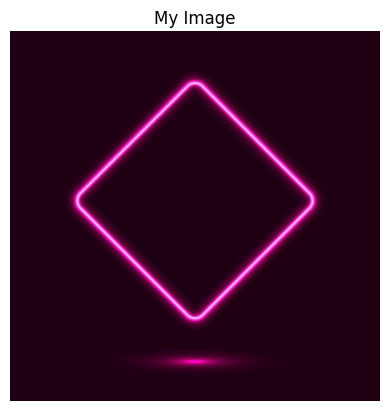

In [68]:
# Download the image from the drive link above
# Upload it to your current working directory in colab
# Load the image and save it under I variable
I = io.imread("/content/sample_data/diamond.jpg")

### Write a code to display the image -
plt.imshow(I,cmap='gray')
plt.axis('off')
plt.title("My Image")
plt.show()
### Code ends

The diamond in the image has two parallel sides. You will need to come up with two $3\times3$ kernels to detect the two sets of parallel sides. Your filters should not detect all the four sides at once.

In [69]:
# Define the 2 custom kernels by replacing the "?"s with your values
# After finding out the values, uncomment the next few lines of code in this cell
# Sebel-like kernel (vertical edges)
kernel_1 = np.array([[-1, 0, 1],
                     [-2, 0, 2],
                     [-1, 0, 1]])
# sharpening kernel
kernel_2 = np.array([[0, -1, 0],
                     [-1, 5, -1],
                     [0, -1, 0]])

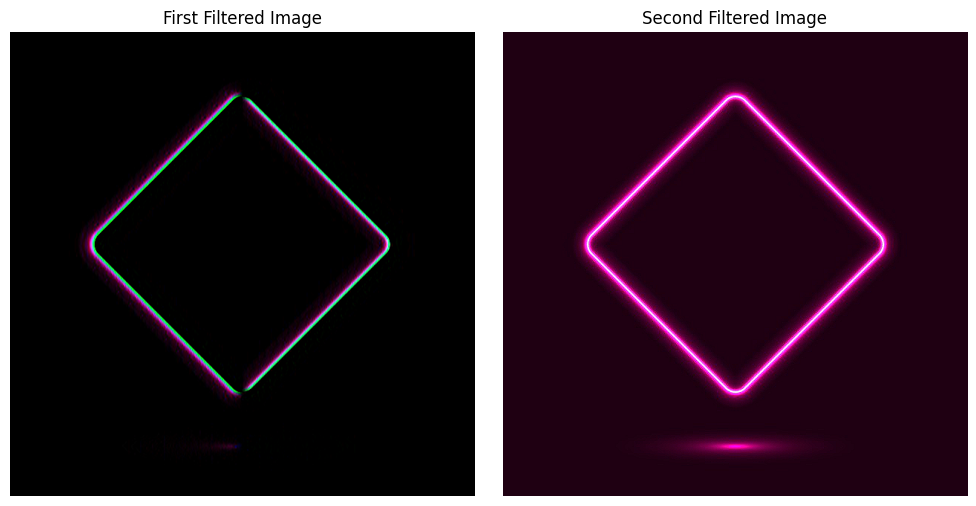

In [70]:
# Apply kernel_1 on I and save it as first_pair
first_pair = cv2.filter2D(I,-1,kernel_1)

# Apply kernel_2 on I and save it as second_pair
second_pair = cv2.filter2D(I,-1,kernel_2)

### Write a code to display the two filtered images side by side in a subplot
fig,axes = plt.subplots(1,2,figsize=(10,5))
axes[0].imshow(first_pair,cmap='gray')
axes[0].set_title('First Filtered Image')
axes[0].axis('off')

axes[1].imshow(second_pair,cmap='gray')
axes[1].set_title('Second Filtered Image')
axes[1].axis('off')
plt.tight_layout()
plt.show()
### Code ends

**Q1. Which filters did you use and why?**

*Answer - I used the following filters:

Direct convolution (convolve2d) – to process the image in the spatial domain.

FFT convolution (fftconvolve) – to process large kernels faster in the frequency domain.

Symmetric kernel – to preserve features like edges and patterns while ensuring correlation and convolution outputs are identical.

Asymmetric kernel – to observe the effect of flipping the kernel (correlation vs convolution differences).

Custom 3×3 kernels – one for edge detection and one for sharpening, to highlight important details in the QR code image.

Reason: Each filter was chosen to demonstrate how convolution and correlation work with different kernel types and to process the image so that the QR code could be read.

**Q2. Are your kernels unique or there can be other kernels which can accomplish the same task?**

*Answer -The kernels I used are not unique.

Many other kernels can accomplish the same task:

For edge detection, different Sobel, Prewitt, or custom high-pass kernels can work.

For sharpening, other kernels with a strong center weight and smaller surrounding negative weights can achieve similar results.

The choice of kernel depends on the specific effect desired, kernel size, and image properties.